In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
np.random.seed(42)

n = 300

data = pd.DataFrame({
    "Attendance": np.random.randint(40, 101, n),
    "Assignment_Completion": np.random.randint(20, 101, n),
    "Test_Score": np.random.randint(20, 101, n),
    "Group": np.random.choice(["Group A", "Group B"], n)
})

def teacher_decision(row):
    attendance = row["Attendance"]
    assignments = row["Assignment_Completion"]
    score = row["Test_Score"]

    # Example decisions provided by a hypothetical teacher
    if attendance < 60 or (score < 35 and assignments < 50):
        return "Intensive Mentoring"
    elif attendance < 75 or score < 60 or assignments < 60:
        return "Additional Support"
    else:
        return "Regular Guidance"

data["Human_Decision"] = data.apply(teacher_decision, axis=1)

print(data.head(10))
print("\nDataset shape:", data.shape)
print("\nDecision distribution:")
print(data["Human_Decision"].value_counts())

   Attendance  Assignment_Completion  Test_Score    Group       Human_Decision
0          78                     30          71  Group A   Additional Support
1          91                     35          72  Group B   Additional Support
2          68                     92          42  Group B   Additional Support
3          54                     78          35  Group B  Intensive Mentoring
4          82                     89          76  Group B     Regular Guidance
5          47                     99          58  Group B  Intensive Mentoring
6         100                     22          72  Group A   Additional Support
7          60                     39          61  Group B   Additional Support
8          78                     78          77  Group A     Regular Guidance
9          97                     55          58  Group A   Additional Support

Dataset shape: (300, 5)

Decision distribution:
Human_Decision
Additional Support     163
Intensive Mentoring    107
Regular Guida

Exercise 1: Develop the Expert System

In [ ]:
# Knowledge base
rules = [
    {
        "name": "Rule 1",
        "condition": "Attendance < 60",
        "recommendation": "Intensive Mentoring"
    },
    {
        "name": "Rule 2",
        "condition": "Test Score < 35 AND Assignments < 50",
        "recommendation": "Intensive Mentoring"
    },
    {
        "name": "Rule 3",
        "condition": "Attendance < 75 OR Test Score < 60 OR Assignments < 60",
        "recommendation": "Additional Support"
    },
    {
        "name": "Rule 4",
        "condition": "No previous rule matched",
        "recommendation": "Regular Guidance"
    }
]

# Inference engine
def expert_system(attendance, assignments, score):
    if attendance < 60:
        return "Intensive Mentoring", "Rule 1: Attendance < 60"

    elif score < 35 and assignments < 50:
        return "Intensive Mentoring", "Rule 2: Low score and low assignments"

    elif attendance < 75 or score < 60 or assignments < 60:
        return "Additional Support", "Rule 3: At least one academic factor is low"

    else:
        return "Regular Guidance", "Rule 4: No risk condition detected"

# Test the expert system
test_students = [
    (50, 40, 30),
    (80, 45, 55),
    (90, 90, 85)
]

for attendance, assignments, score in test_students:
    result, explanation = expert_system(
        attendance, assignments, score
    )
    print(f"\nAttendance: {attendance}%")
    print(f"Assignments: {assignments}%")
    print(f"Test Score: {score}")
    print("Recommendation:", result)
    print("Reason:", explanation)


Attendance: 50%
Assignments: 40%
Test Score: 30
Recommendation: Intensive Mentoring
Reason: Rule 1: Attendance < 60

Attendance: 80%
Assignments: 45%
Test Score: 55
Recommendation: Additional Support
Reason: Rule 3: At least one academic factor is low

Attendance: 90%
Assignments: 90%
Test Score: 85
Recommendation: Regular Guidance
Reason: Rule 4: No risk condition detected


Exercise 2: Imitation Learning

In [ ]:
#Prepare the training data
features = [
    "Attendance",
    "Assignment_Completion",
    "Test_Score"
]

X = data[features]
y = data["Human_Decision"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 240
Testing examples: 60


In [ ]:
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 100.0 %

Classification Report:

                     precision    recall  f1-score   support

 Additional Support       1.00      1.00      1.00        33
Intensive Mentoring       1.00      1.00      1.00        21
   Regular Guidance       1.00      1.00      1.00         6

           accuracy                           1.00        60
          macro avg       1.00      1.00      1.00        60
       weighted avg       1.00      1.00      1.00        60



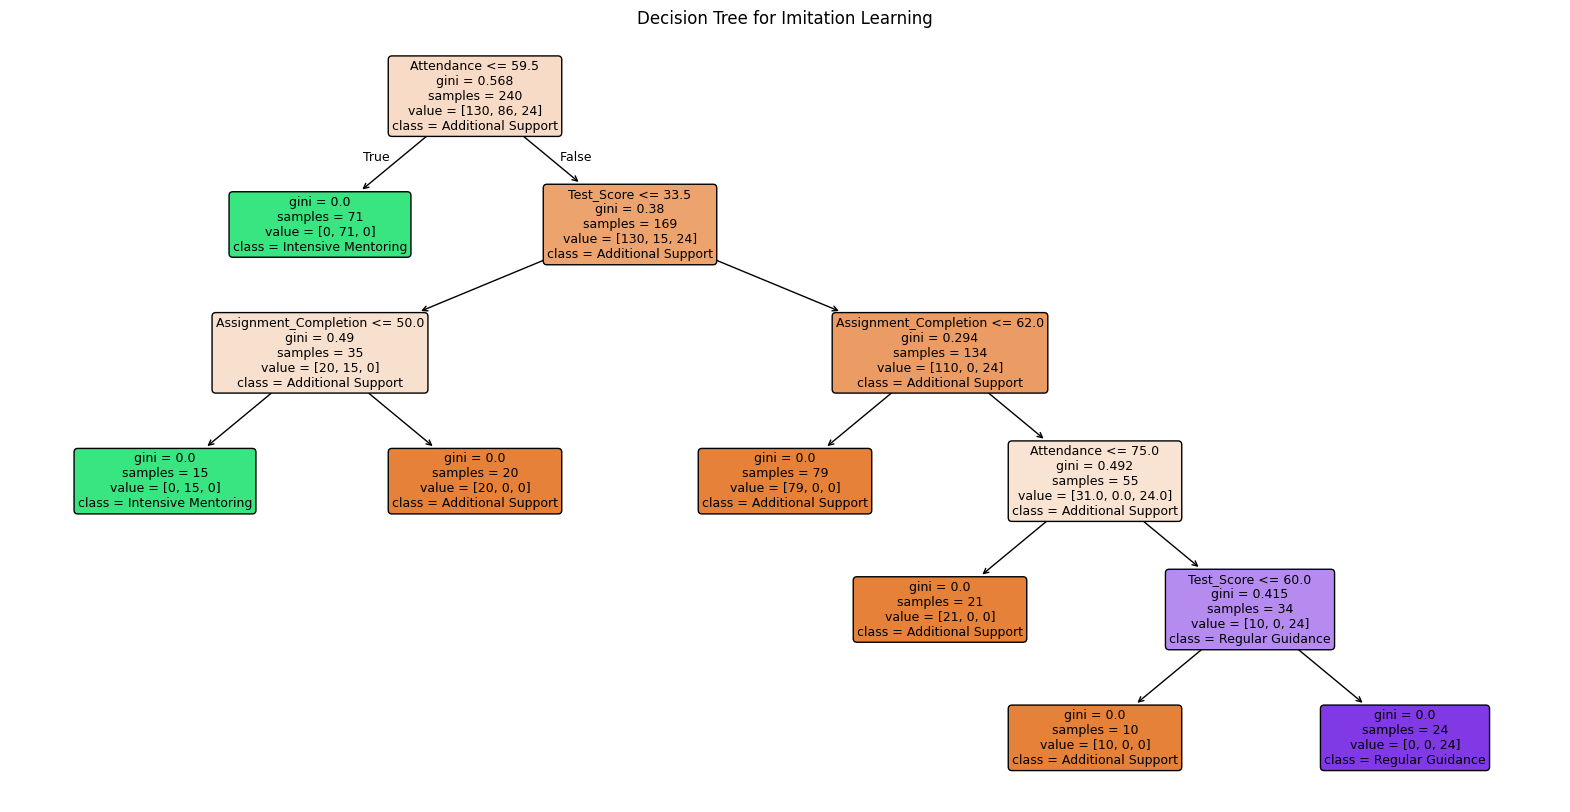

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree for Imitation Learning")
plt.show()

Exercise 3: Add an Explanation Facility

In [ ]:
def explain_decision(attendance, assignments, score):
    recommendation, reason = expert_system(
        attendance, assignments, score
    )

    student = pd.DataFrame([{
        "Attendance": attendance,
        "Assignment_Completion": assignments,
        "Test_Score": score
    }])

    ml_prediction = model.predict(student)[0]

    print("STUDENT ACADEMIC SUPPORT REPORT")
    print("-" * 40)
    print(f"Attendance: {attendance}%")
    print(f"Assignment Completion: {assignments}%")
    print(f"Test Score: {score}")
    print()
    print("Expert System Recommendation:", recommendation)
    print("Explanation:", reason)
    print()
    print("Imitation Model Prediction:", ml_prediction)

    if recommendation != ml_prediction:
        print("\nNote: The rule-based system and learned model disagree.")

# Try an example
explain_decision(
    attendance=55,
    assignments=45,
    score=40
)

STUDENT ACADEMIC SUPPORT REPORT
----------------------------------------
Attendance: 55%
Assignment Completion: 45%
Test Score: 40

Expert System Recommendation: Intensive Mentoring
Explanation: Rule 1: Attendance < 60

Imitation Model Prediction: Intensive Mentoring


Attendance               0.623636
Assignment_Completion    0.216265
Test_Score               0.160099
dtype: float64


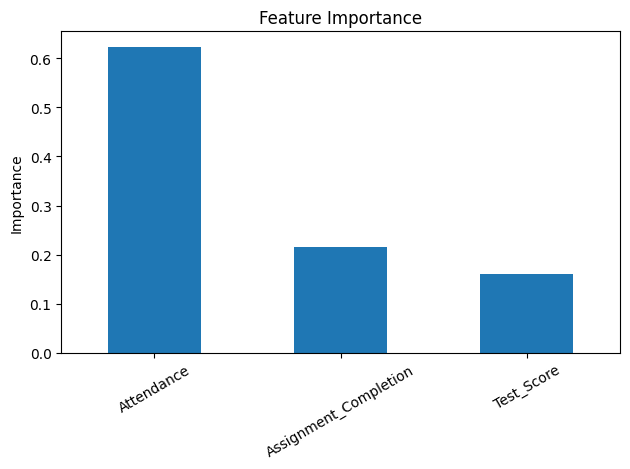

In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

importance.plot(kind="bar", title="Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Exercise 4: Ethical AI and Fairness Evaluation

In [ ]:
# Generate recommendations for all students
data["Expert_Recommendation"] = data.apply(
    lambda row: expert_system(
        row["Attendance"],
        row["Assignment_Completion"],
        row["Test_Score"]
    )[0],
    axis=1
)

data["ML_Recommendation"] = model.predict(data[features])

# Convert recommendations into a binary outcome for auditing:
# 1 = receives additional support or intensive mentoring
# 0 = receives regular guidance

data["Expert_Needs_Support"] = (
    data["Expert_Recommendation"] != "Regular Guidance"
).astype(int)

data["ML_Needs_Support"] = (
    data["ML_Recommendation"] != "Regular Guidance"
).astype(int)

fairness_report = data.groupby("Group").agg(
    Students=("Group", "size"),
    Expert_Support_Rate=("Expert_Needs_Support", "mean"),
    ML_Support_Rate=("ML_Needs_Support", "mean")
)

fairness_report["Expert_Support_Rate"] *= 100
fairness_report["ML_Support_Rate"] *= 100

print("FAIRNESS REPORT (%)")
print(fairness_report.round(2))

FAIRNESS REPORT (%)
         Students  Expert_Support_Rate  ML_Support_Rate
Group                                                  
Group A       148                93.24            93.24
Group B       152                86.84            86.84


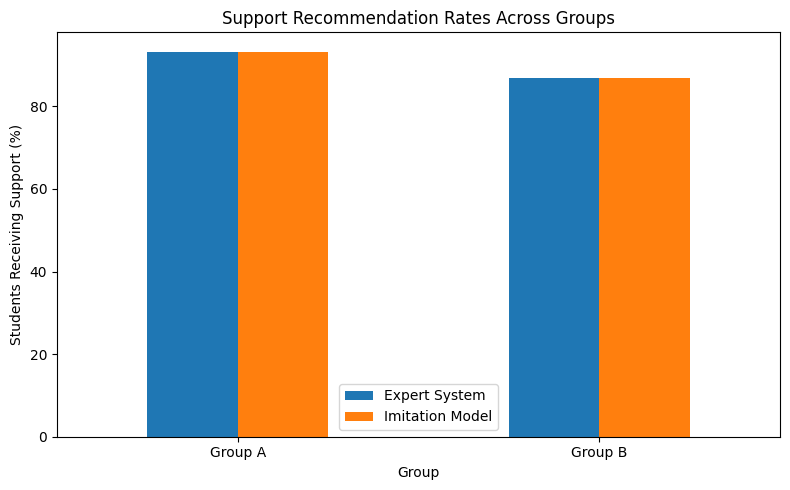

In [ ]:
fairness_report[
    ["Expert_Support_Rate", "ML_Support_Rate"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Support Recommendation Rates Across Groups")
plt.ylabel("Students Receiving Support (%)")
plt.xlabel("Group")
plt.xticks(rotation=0)
plt.legend(["Expert System", "Imitation Model"])
plt.tight_layout()
plt.show()

In [ ]:
expert_gap = abs(
    fairness_report.loc["Group A", "Expert_Support_Rate"]
    - fairness_report.loc["Group B", "Expert_Support_Rate"]
)

ml_gap = abs(
    fairness_report.loc["Group A", "ML_Support_Rate"]
    - fairness_report.loc["Group B", "ML_Support_Rate"]
)

print("Expert System Support-Rate Gap:", round(expert_gap, 2), "percentage points")
print("Imitation Model Support-Rate Gap:", round(ml_gap, 2), "percentage points")

if ml_gap > 10:
    print("Audit flag: The model has a noticeable difference in group support rates.")
else:
    print("Audit result: The group support-rate gap is within 10 percentage points.")

Expert System Support-Rate Gap: 6.4 percentage points
Imitation Model Support-Rate Gap: 6.4 percentage points
Audit result: The group support-rate gap is within 10 percentage points.


Exercise 5: Testing and Comparison

In [ ]:
data["Before_Change"] = data["Expert_Recommendation"].copy()

before_counts = data["Before_Change"].value_counts()

print("Recommendations BEFORE rule change:")
print(before_counts)

Recommendations BEFORE rule change:
Before_Change
Additional Support     163
Intensive Mentoring    107
Regular Guidance        30
Name: count, dtype: int64


In [ ]:
def modified_expert_system(attendance, assignments, score):
    if attendance < 60:
        return "Intensive Mentoring"

    elif score < 35 and assignments < 50:
        return "Intensive Mentoring"

    # Changed attendance threshold from 75 to 65
    elif attendance < 65 or score < 60 or assignments < 60:
        return "Additional Support"

    else:
        return "Regular Guidance"

data["After_Change"] = data.apply(
    lambda row: modified_expert_system(
        row["Attendance"],
        row["Assignment_Completion"],
        row["Test_Score"]
    ),
    axis=1
)

print("Recommendations AFTER rule change:")
print(data["After_Change"].value_counts())

Recommendations AFTER rule change:
After_Change
Additional Support     150
Intensive Mentoring    107
Regular Guidance        43
Name: count, dtype: int64


                     Before Change  After Change
Regular Guidance                30            43
Additional Support             163           150
Intensive Mentoring            107           107


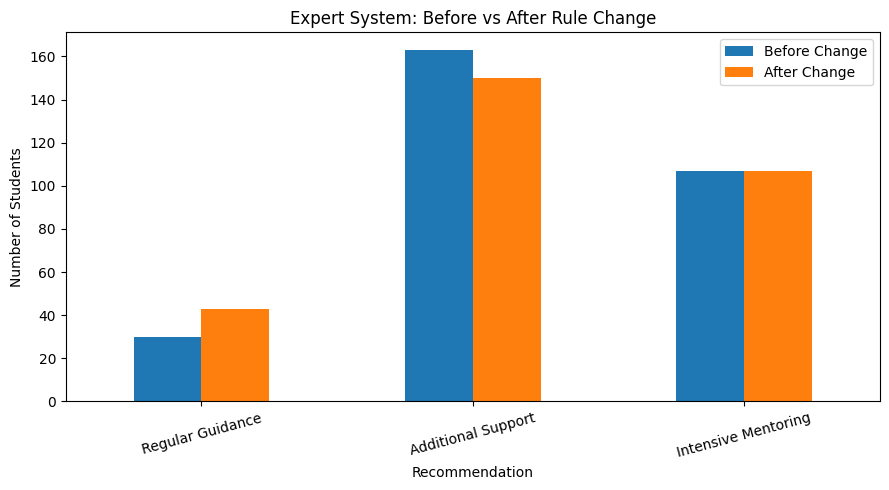

In [ ]:
comparison = pd.DataFrame({
    "Before Change": data["Before_Change"].value_counts(),
    "After Change": data["After_Change"].value_counts()
}).fillna(0).astype(int)

comparison = comparison.reindex([
    "Regular Guidance",
    "Additional Support",
    "Intensive Mentoring"
], fill_value=0)

print(comparison)

comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Expert System: Before vs After Rule Change")
plt.ylabel("Number of Students")
plt.xlabel("Recommendation")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
changed_students = data[
    data["Before_Change"] != data["After_Change"]
]

print("Number of students affected:", len(changed_students))

print(changed_students[[
    "Attendance",
    "Assignment_Completion",
    "Test_Score",
    "Before_Change",
    "After_Change"
]].head(15))

Number of students affected: 13
     Attendance  Assignment_Completion  Test_Score       Before_Change  \
91           68                     83          76  Additional Support   
138          74                     84          96  Additional Support   
153          72                     77          93  Additional Support   
163          66                     72          84  Additional Support   
166          74                     87          91  Additional Support   
177          66                     82          76  Additional Support   
181          65                     81          98  Additional Support   
193          69                     83          82  Additional Support   
208          67                     88          88  Additional Support   
227          72                     99          86  Additional Support   
250          71                     65          92  Additional Support   
284          71                     78          76  Additional Support   
286   

               System  Accuracy (%)
0       Expert System         100.0
1  Imitation Learning         100.0


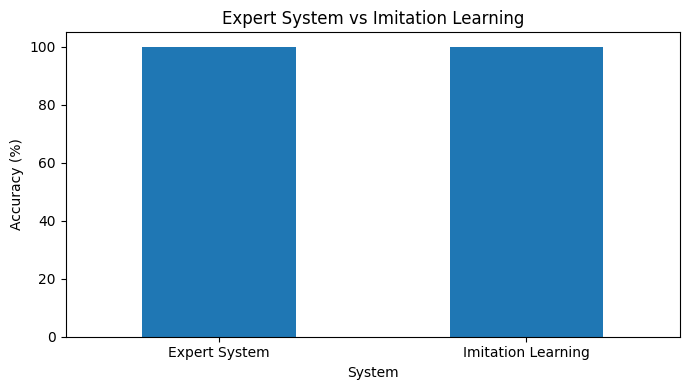

In [ ]:
# Expert System predictions on the test set
expert_test_predictions = X_test.apply(
    lambda row: expert_system(
        row["Attendance"],
        row["Assignment_Completion"],
        row["Test_Score"]
    )[0],
    axis=1
)

# Compare both systems against the human decisions
expert_accuracy = accuracy_score(y_test, expert_test_predictions)
ml_accuracy = accuracy_score(y_test, model.predict(X_test))

results = pd.DataFrame({
    "System": ["Expert System", "Imitation Learning"],
    "Accuracy (%)": [
        round(expert_accuracy * 100, 2),
        round(ml_accuracy * 100, 2)
    ]
})

print(results)

results.plot(
    x="System",
    y="Accuracy (%)",
    kind="bar",
    legend=False,
    figsize=(7, 4)
)

plt.title("Expert System vs Imitation Learning")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.ylim(0, 105)
plt.tight_layout()
plt.show()